# 07 · Experimentos de reentrenamiento

**Objetivo:** probar estrategias que **sí reentrenan** para mejorar el rendimiento con fotos propias, y medir con honestidad cuánto aporta cada una.

| Fase | Qué se prueba | Cómo se evalúa |
|---|---|---|
| **1** | Aumento de datos fuerte, label smoothing, mayor resolución, más capas descongeladas | Con **todas** tus fotos (no se entrena con ellas) |
| **2** | Fine-tuning con parte de tus fotos | **Leave-one-session-out**: se entrena con todas las sesiones menos una y se evalúa en la que quedó fuera |
| **3** | Entrenamiento final con todo el dataset y la mejor configuración | Con todas tus fotos |

**Para que los experimentos sean rápidos:** la Fase 1 usa una **muestra** del dataset (700 imágenes por clase en entrenamiento, 20.300 en total). El dataset tiene fotos casi idénticas entre sí, así que debería conservar buena parte del efecto, pero **se comprueba**: la corrida A (referencia) se compara con el MobileNetV2 entrenado con todo el dataset.

**Requisitos:** haber ejecutado el notebook 06 (genera `data/sesiones.csv`). Las celdas de entrenamiento pueden tardar y **se reanudan solas** si se interrumpen: basta con volver a ejecutarlas.

> **Límites a tener en cuenta:** las sesiones son una aproximación, y con 3 personas la misma persona puede aparecer en el entrenamiento y en la sesión retenida (resultados algo optimistas). Con ~460 fotos de pocas condiciones, diferencias pequeñas pueden ser ruido.

In [2]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow import keras

from src.train import train, load_config, _setup_gpu
_setup_gpu()
from src.data import list_classes
from src.compare import latest_run, summarize_run
from src.visualize import list_own_photos, predict_own_photos, load_images
from src.own_photos import load_sessions
from src.finetune_own import replay_sample, leave_one_session_out
import src.improve as imp

RAW = load_config("configs/baseline.yaml")["data"]["raw_dir"]
NORM = ROOT / "data" / "mis_fotos_200"
SESIONES_CSV = ROOT / "data" / "sesiones.csv"
assert SESIONES_CSV.exists(), "Falta data/sesiones.csv: ejecuta antes el notebook 06 (paso 2)"

class_names = list_classes(RAW)
photos = load_sessions(list_own_photos(NORM, class_names), NORM, SESIONES_CSV)
print(f"{len(photos)} fotos | sesiones: {photos.sesion.value_counts().sort_index().to_dict()}")


def evaluar_run(rd):
    """Métricas con TODAS las fotos propias de una corrida terminada (no entrenada con ellas)."""
    size = tuple(load_config(rd / "config.yaml")["data"]["img_size"])
    modelo = keras.models.load_model(rd / "final" / "model.keras", compile=False)
    res, _, _ = predict_own_photos(modelo, photos, class_names, size)
    keras.backend.clear_session()
    return imp.own_metrics(res)

I0000 00:00:1794684589.075772    3840 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
460 fotos | sesiones: {'fondo-1': 142, 'fondo-2': 136, 'fondo-3': 133, 'fondo-4': 49}


# Fase 1 · Estrategias de entrenamiento (con una muestra del dataset)

## Ver el aumento de datos fuerte
Antes de entrenar, conviene ver cómo queda. Cada fila es una foto original y siete versiones aleatorias con el aumento del experimento B: zoom entre ~0,77× y ~1,43×, traslación de hasta 10 %, cambios de brillo, contraste y saturación, desenfoque y borrado de parches, con rotación de hasta ±11° (menos que el ±18° original, porque I y J se distinguen por la orientación). **Comprueba que la seña sigue siendo reconocible a ojo**: si el aumento la destruye, es demasiado fuerte.

I0000 00:00:1794668812.022198    6342 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


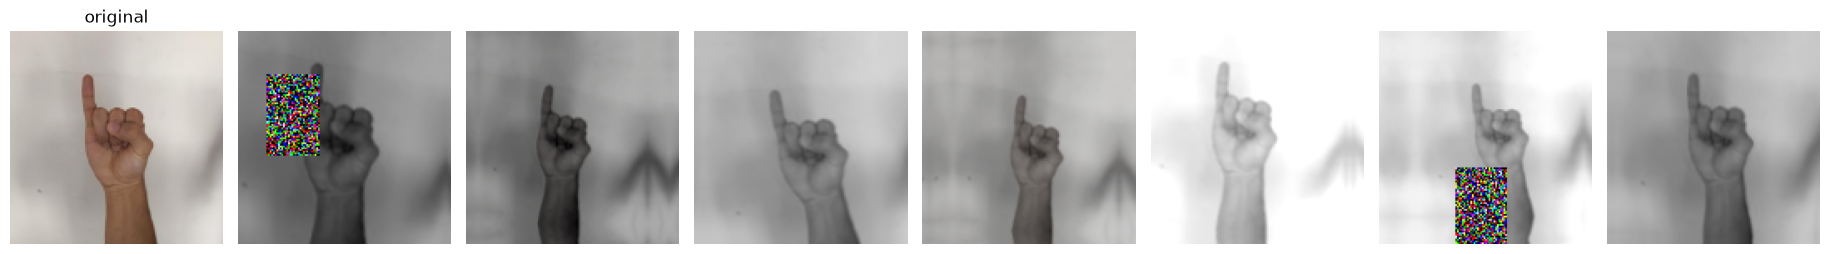

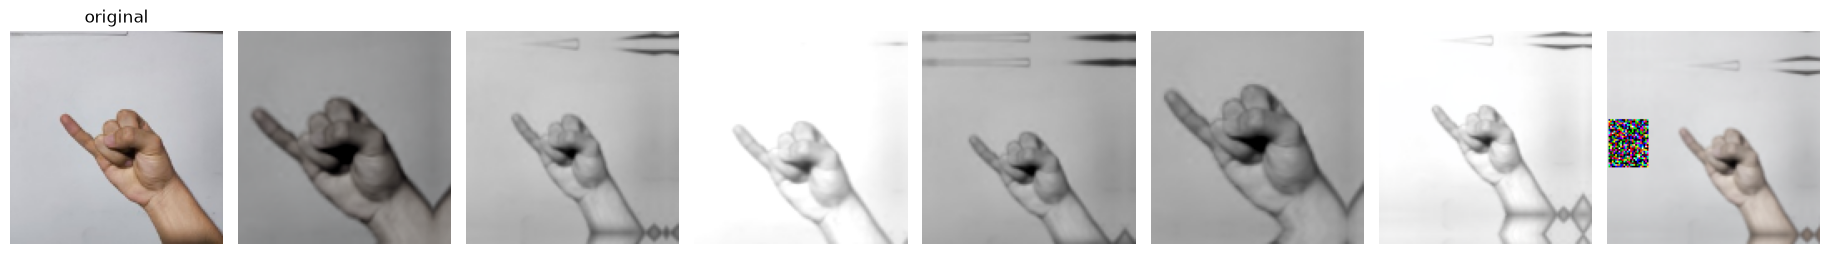

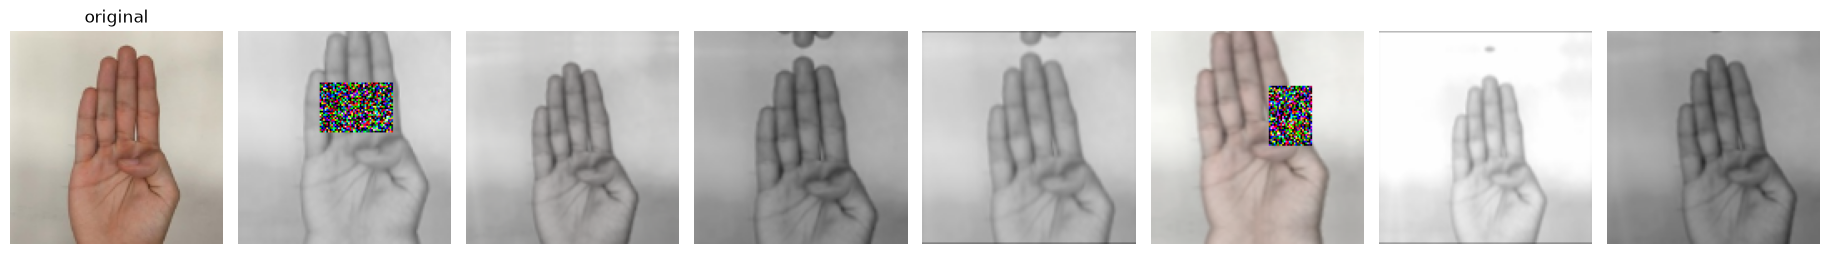

In [2]:
cfg_b = load_config("configs/exp_b_aumento_fuerte.yaml")
for letra in ["I", "J", "B"]:
    sub = photos[photos.label == letra]
    if sub.empty:
        continue
    imp.preview_augmentation(cfg_b, load_images([sub.iloc[0].path], (128, 128))[0], n=7)

## Los experimentos
Todos usan MobileNetV2 (la más rápida), la misma muestra del dataset, la misma semilla y el mismo número de épocas, para que la comparación sea limpia. **Cada uno cambia una sola cosa** respecto a B (salvo A, que es la referencia):

| | Qué cambia | Idea |
|---|---|---|
| **A** | Aumento básico original | Referencia |
| **B** | Aumento fuerte | Cambio de dominio: variación de escala, luz y fondo |
| **C** | B + label smoothing 0,1 | Menos sobreconfianza |
| **D** | B a 192×192 | Más detalle (pulgar en los puños cerrados) |
| **E** | B con 80 capas descongeladas y 12 épocas | Más capacidad de ajuste |

Los tiempos no los conozco: ejecuta primero A y B, mide cuánto tarda cada una y decide si lanzas C, D y E. D será la más lenta (más píxeles). Si se interrumpe una celda, vuelve a ejecutarla y reanuda.

### Experimento A · aumento básico (referencia)

In [3]:
train("configs/exp_a_aumento_basico.yaml", name="exp_a")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1006_exp_a (nueva) | modelo: mobilenetv2
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3


I0000 00:00:1794668821.113378    6452 cuda_dnn.cc:461] Loaded cuDNN version 92700


318/318 - 26s - 83ms/step - accuracy: 0.5555 - loss: 1.5637 - val_accuracy: 0.8579 - val_loss: 0.5405 - learning_rate: 0.0010
Epoch 2/3
318/318 - 19s - 58ms/step - accuracy: 0.7845 - loss: 0.7202 - val_accuracy: 0.8969 - val_loss: 0.3748 - learning_rate: 0.0010
Epoch 3/3
318/318 - 18s - 56ms/step - accuracy: 0.8257 - loss: 0.5685 - val_accuracy: 0.8800 - val_loss: 0.3711 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 30 capas, épocas 4-12
Epoch 4/12
318/318 - 32s - 100ms/step - accuracy: 0.8945 - loss: 0.3189 - val_accuracy: 0.9383 - val_loss: 0.1866 - learning_rate: 5.0000e-05
Epoch 5/12
318/318 - 24s - 74ms/step - accuracy: 0.9400 - loss: 0.1810 - val_accuracy: 0.9548 - val_loss: 0.1376 - learning_rate: 5.0000e-05
Epoch 6/12
318/318 - 23s - 73ms/step - accuracy: 0.9576 - loss: 0.1304 - val_accuracy: 0.9686 - val_loss: 0.0922 - learning_rate: 5.0000e-05
Epoch 7/12
318/318 - 23s - 73ms/step - accuracy: 0.9691 - loss: 0.0923 - val_accuracy: 0.9772 - val_loss: 0.0604 - le

PosixPath('experiments/20261114-1006_exp_a')

### Experimento B · aumento fuerte

In [4]:
train("configs/exp_b_aumento_fuerte.yaml", name="exp_b")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1011_exp_b (nueva) | modelo: mobilenetv2
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
318/318 - 25s - 80ms/step - accuracy: 0.4408 - loss: 1.9877 - val_accuracy: 0.7190 - val_loss: 0.9441 - learning_rate: 0.0010
Epoch 2/3
318/318 - 21s - 66ms/step - accuracy: 0.6343 - loss: 1.2374 - val_accuracy: 0.7641 - val_loss: 0.7723 - learning_rate: 0.0010
Epoch 3/3
318/318 - 21s - 67ms/step - accuracy: 0.6883 - loss: 1.0569 - val_accuracy: 0.7848 - val_loss: 0.7089 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 30 capas, épocas 4-12
Epoch 4/12
318/318 - 30s - 94ms/step - accuracy: 0.7669 - loss: 0.7544 - val_accuracy: 0.8866 - val_loss: 0.3295 - learning_rate: 5.0000e-05
Epoch 5/12
318/318 - 24s - 77ms/step - accuracy: 0.8294 - loss: 0.5378 - val_accuracy: 0.9172 - val_loss: 0.2259 - learning_rate: 5.0000e-05
Epoch 6/12
318/318 - 25s - 79ms/step - accurac

PosixPath('experiments/20261114-1011_exp_b')

### Experimento C · aumento fuerte + label smoothing

In [5]:
train("configs/exp_c_aumento_fuerte_ls.yaml", name="exp_c")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1016_exp_c (nueva) | modelo: mobilenetv2
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
318/318 - 26s - 82ms/step - accuracy: 0.4349 - loss: 2.3267 - val_accuracy: 0.7148 - val_loss: 1.4928 - learning_rate: 0.0010
Epoch 2/3
318/318 - 21s - 67ms/step - accuracy: 0.6298 - loss: 1.7568 - val_accuracy: 0.7614 - val_loss: 1.3968 - learning_rate: 0.0010
Epoch 3/3
318/318 - 21s - 66ms/step - accuracy: 0.6820 - loss: 1.6269 - val_accuracy: 0.7845 - val_loss: 1.3638 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 30 capas, épocas 4-12
Epoch 4/12
318/318 - 31s - 97ms/step - accuracy: 0.7690 - loss: 1.3897 - val_accuracy: 0.8872 - val_loss: 1.0813 - learning_rate: 5.0000e-05
Epoch 5/12
318/318 - 25s - 80ms/step - accuracy: 0.8368 - loss: 1.2112 - val_accuracy: 0.9221 - val_loss: 0.9885 - learning_rate: 5.0000e-05
Epoch 6/12
318/318 - 26s - 82ms/step - accurac

PosixPath('experiments/20261114-1016_exp_c')

### Experimento D · aumento fuerte a 192×192

In [6]:
train("configs/exp_d_aumento_fuerte_192.yaml", name="exp_d")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1021_exp_d (nueva) | modelo: mobilenetv2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
318/318 - 38s - 121ms/step - accuracy: 0.4553 - loss: 1.9467 - val_accuracy: 0.7372 - val_loss: 0.9771 - learning_rate: 0.0010
Epoch 2/3
318/318 - 33s - 103ms/step - accuracy: 0.6646 - loss: 1.1620 - val_accuracy: 0.7955 - val_loss: 0.7451 - learning_rate: 0.0010
Epoch 3/3
318/318 - 32s - 102ms/step - accuracy: 0.7180 - loss: 0.9732 - val_accuracy: 0.8224 - val_loss: 0.6238 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 30 capas, épocas 4-12
Epoch 4/12
318/318 - 46s - 145ms/step - accuracy: 0.8165 - loss: 0.5989 - val_accuracy: 0.9262 - val_loss: 0.2240 - learning_rate: 5.0000e-05
Epoch 5/12
318/318 - 39s - 123ms/step - accuracy: 0.8796 - loss: 0.3915 - val_accuracy: 0.9521 - val_loss: 0.1613 - learning_rate: 5.0

PosixPath('experiments/20261114-1021_exp_d')

### Experimento E · aumento fuerte + más capas descongeladas

In [7]:
train("configs/exp_e_aumento_fuerte_mas_capas.yaml", name="exp_e")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1029_exp_e (nueva) | modelo: mobilenetv2
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
318/318 - 26s - 83ms/step - accuracy: 0.4408 - loss: 1.9877 - val_accuracy: 0.7190 - val_loss: 0.9441 - learning_rate: 0.0010
Epoch 2/3
318/318 - 21s - 65ms/step - accuracy: 0.6343 - loss: 1.2374 - val_accuracy: 0.7641 - val_loss: 0.7723 - learning_rate: 0.0010
Epoch 3/3
318/318 - 21s - 65ms/step - accuracy: 0.6883 - loss: 1.0569 - val_accuracy: 0.7848 - val_loss: 0.7089 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 80 capas, épocas 4-15
Epoch 4/15
318/318 - 45s - 140ms/step - accuracy: 0.8272 - loss: 0.5635 - val_accuracy: 0.9603 - val_loss: 0.1196 - learning_rate: 5.0000e-05
Epoch 5/15
318/318 - 31s - 97ms/step - accuracy: 0.9045 - loss: 0.2987 - val_accuracy: 0.9828 - val_loss: 0.0592 - learning_rate: 5.0000e-05
Epoch 6/15
318/318 - 31s - 96ms/step - accura

PosixPath('experiments/20261114-1029_exp_e')

## Comparación de la Fase 1
Se evalúan las corridas que existan con **todas** tus fotos (ninguna se entrenó con ellas, así que es una prueba limpia). Se incluye el MobileNetV2 entrenado con todo el dataset (notebook 04) como referencia.

**Cómo leer la tabla**
- **accuracy** es la medida principal. **Accuracy por sesión** indica si la mejora es general o solo en algún fondo.
- **A frente a MobileNetV2 completo:** si son parecidos, la muestra del dataset es un buen atajo; si A es mucho peor, los resultados de las demás corridas hay que tomarlos con cautela.
- **B frente a A** mide el efecto del aumento fuerte; **C, D y E frente a B**, el de cada cambio adicional.
- **Confianza media en errores** y **% a la clase refugio** deberían bajar si el modelo mejora de verdad.
- **test dataset** (accuracy en la muestra de test del dataset) es solo un control: debe seguir muy alto. Si cae, el aumento está dañando el aprendizaje.
- **Ruido:** con ~460 fotos, 2-3 puntos de diferencia pueden ser azar.

,accuracy,confianza media en errores,clase refugio,% predicciones a la refugio,acc fondo-1,acc fondo-2,acc fondo-3,acc fondo-4,test dataset,épocas,s/época
A · básico,0.413,0.777,Z,0.143,0.387,0.426,0.444,0.367,0.9845,12,23.2
B · fuerte,0.5304,0.677,H,0.126,0.563,0.515,0.586,0.327,0.9679,12,24.4
C · fuerte + label smoothing,0.5109,0.204,H,0.109,0.535,0.478,0.564,0.388,0.9683,12,25.1
D · fuerte 192 px,0.5435,0.678,H,0.117,0.507,0.537,0.617,0.469,0.9886,12,38.2
E · fuerte + más capas,0.6217,0.695,S,0.083,0.662,0.603,0.677,0.408,0.9962,11,30.6
MobileNetV2 completo (nb 04),0.5391,0.795,S,0.107,0.577,0.544,0.586,0.286,0.9977,15,66.1


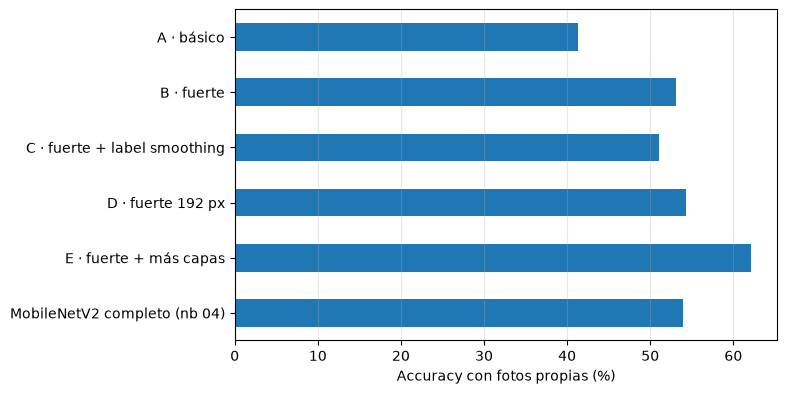

In [16]:
candidatas = [("A · básico", "exp_a"), ("B · fuerte", "exp_b"), ("C · fuerte + label smoothing", "exp_c"),
              ("D · fuerte 192 px", "exp_d"), ("E · fuerte + más capas", "exp_e"),
              ("MobileNetV2 completo (nb 04)" , "mobilenetv2")]
runs_f1 = {}
for etiqueta, nombre in candidatas:
    try:
        runs_f1[etiqueta] = latest_run(nombre)
    except FileNotFoundError:
        print(f"(aún no hay una corrida terminada de '{nombre}')")

filas = {}
for etiqueta, rd in runs_f1.items():
    s = summarize_run(rd)
    filas[etiqueta] = {**evaluar_run(rd), "test dataset": s["test accuracy"], "épocas": s["épocas"], "s/época": s["s/época (mediana)"]}
fase1 = pd.DataFrame(filas).T
display(fase1)

ax = fase1["accuracy"].astype(float).mul(100).plot.barh(figsize=(7, 0.55 * len(fase1) + 1))
ax.set_xlabel("Accuracy con fotos propias (%)")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.show()

# Fase 2 · Fine-tuning con tus fotos (leave-one-session-out)

Aquí sí se entrena con fotos propias. Para no engañarnos, el procedimiento es:
1. Se toma un modelo ya entrenado (el de la Fase 1 que mejor haya salido, o el MobileNetV2 completo).
2. Para cada sesión: se ajusta con las fotos de **todas las demás** sesiones y se evalúa en la sesión que quedó **fuera**.
3. Las fotos de entrenamiento se repiten varias veces (`oversample`) y se mezclan con una muestra del dataset (`replay`) para que no olvide lo que ya sabe.
4. **Número de épocas y learning rate se fijan antes de ver resultados**: nada se elige con las fotos retenidas.

**Cómo leer la tabla:** `antes` es el modelo sin ajustar evaluado en esa misma sesión; `después`, tras el fine-tuning. La diferencia es lo que aportan tus fotos. Una mejora clara en todas las sesiones indica que la variedad de datos es la palanca principal y que tomar más fotos compensa. Una mejora pequeña o desigual indica que 460 fotos de pocas condiciones no bastan.

**Límite importante:** como las sesiones son aproximadas y hay solo 3 personas, la misma persona puede estar en el entrenamiento y en la sesión retenida. Los resultados serán algo optimistas respecto a una persona completamente nueva.

In [10]:
BASE = "exp_e"   # nombre de la corrida a ajustar: pon aquí el experimento que mejor haya salido en la Fase 1
EPOCAS, LR, OVERSAMPLE = 6, 3e-5, 5

rd = latest_run(BASE)
cfg_base = load_config(rd / "config.yaml")
size = tuple(cfg_base["data"]["img_size"])
replay = replay_sample(cfg_base, per_class=100)

print(f"Fine-tuning de '{rd.name}' | {EPOCAS} épocas, lr {LR}, fotos propias x{OVERSAMPLE} + {len(replay)} imágenes del dataset")
ft_mejor = leave_one_session_out(rd / "final" / "model.keras", photos, replay, class_names, size,
                                 epochs=EPOCAS, lr=LR, oversample=OVERSAMPLE)
display(ft_mejor)

Fine-tuning de '20261114-1029_exp_e' | 6 épocas, lr 3e-05, fotos propias x5 + 2900 imágenes del dataset
  fondo-1: 66.2% → 85.2% (142 fotos retenidas)
  fondo-2: 60.3% → 86.0% (136 fotos retenidas)
  fondo-3: 67.7% → 85.0% (133 fotos retenidas)
  fondo-4: 40.8% → 71.4% (49 fotos retenidas)


,sesión retenida,fotos retenidas,fotos de entrenamiento,antes,después
0,fondo-1,142,318,0.6620,0.8521
1,fondo-2,136,324,0.6029,0.8603
2,fondo-3,133,327,0.6767,0.8496
3,fondo-4,49,411,0.4082,0.7143
4,media ponderada,460,,0.6217,0.8391


### La misma prueba partiendo del MobileNetV2 original
Sirve para separar efectos: si el modelo entrenado con aumento fuerte mejora **más** con tus fotos que el original, el aumento fuerte y las fotos propias se suman; si mejoran parecido, el efecto es principalmente de las fotos.

In [11]:
rd0 = latest_run("mobilenetv2")
size0 = tuple(load_config(rd0 / "config.yaml")["data"]["img_size"])
replay0 = replay_sample(load_config(rd0 / "config.yaml"), per_class=100)

print(f"Fine-tuning de '{rd0.name}'")
ft_original = leave_one_session_out(rd0 / "final" / "model.keras", photos, replay0, class_names, size0,
                                    epochs=EPOCAS, lr=LR, oversample=OVERSAMPLE)
display(ft_original)

Fine-tuning de '20261026-1735_mobilenetv2'
  fondo-1: 57.7% → 78.9% (142 fotos retenidas)
  fondo-2: 54.4% → 70.6% (136 fotos retenidas)
  fondo-3: 58.6% → 76.7% (133 fotos retenidas)
  fondo-4: 28.6% → 51.0% (49 fotos retenidas)


,sesión retenida,fotos retenidas,fotos de entrenamiento,antes,después
0,fondo-1,142,318,0.5775,0.7887
1,fondo-2,136,324,0.5441,0.7059
2,fondo-3,133,327,0.5865,0.7669
3,fondo-4,49,411,0.2857,0.5102
4,media ponderada,460,,0.5391,0.7283


# Fase 3 · Entrenamiento final con todo el dataset

Con la mejor configuración de la Fase 1, se entrena con **todo** el dataset (sin muestra) y se evalúa con tus fotos. La configuración se genera a partir de la del experimento elegido (`MEJOR`), quitando la muestra y ampliando las épocas de fine-tuning. Ajusta `MEJOR` y los valores de la celda según lo que haya salido mejor. Si varios cambios ayudaron (por ejemplo B y C), edita el YAML generado para combinarlos antes de entrenar.

Es la fase más lenta: cada modelo usa los 60.900 ejemplos. EfficientNetB0 es la más pesada.

In [ ]:
MEJOR = "configs/exp_e_aumento_fuerte_mas_capas.yaml"   # config del experimento que mejor salió
EPOCAS_FINETUNE = 20

def config_final(base_cfg, modelo, salida, epochs_finetune, unfreeze=None):
    cfg = load_config(base_cfg)
    cfg["model"]["name"] = modelo
    for k in ("train_per_class", "val_per_class", "test_per_class"):
        cfg["data"].pop(k, None)
    cfg["train"]["epochs_finetune"] = epochs_finetune
    cfg["train"]["early_stopping_patience"] = 4
    if unfreeze:
        cfg["train"]["unfreeze_layers"] = unfreeze
    Path(salida).write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
    return salida

final_mnet = config_final(MEJOR, "mobilenetv2", "configs/final_mobilenetv2.yaml", EPOCAS_FINETUNE)
final_effnet = config_final(MEJOR, "efficientnetb0", "configs/final_efficientnetb0.yaml", EPOCAS_FINETUNE, unfreeze=120)
print("Configs generadas:", final_mnet, "y", final_effnet)

Configs generadas: configs/final_mobilenetv2.yaml y configs/final_efficientnetb0.yaml


### Entrenamiento final · MobileNetV2

In [13]:
train(final_mnet, name="final_mobilenetv2")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1103_final_mobilenetv2 (nueva) | modelo: mobilenetv2
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
952/952 - 69s - 72ms/step - accuracy: 0.5911 - loss: 1.4197 - val_accuracy: 0.8084 - val_loss: 0.6364 - learning_rate: 0.0010
Epoch 2/3
952/952 - 61s - 64ms/step - accuracy: 0.7161 - loss: 0.9573 - val_accuracy: 0.8042 - val_loss: 0.5862 - learning_rate: 0.0010
Epoch 3/3
952/952 - 61s - 64ms/step - accuracy: 0.7318 - loss: 0.9003 - val_accuracy: 0.8302 - val_loss: 0.5281 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 80 capas, épocas 4-23
Epoch 4/23
952/952 - 106s - 112ms/step - accuracy: 0.8897 - loss: 0.3493 - val_accuracy: 0.9903 - val_loss: 0.0316 - learning_rate: 5.0000e-05
Epoch 5/23
952/952 - 99s - 104ms/step - accuracy: 0.9505 - loss: 0.1542 - val_accuracy: 0.9925 - val_loss: 0.0233 - learning_rate: 5.0000e-05
Epoch 6/23
952/952 - 93s - 98ms

PosixPath('experiments/20261114-1103_final_mobilenetv2')

### Entrenamiento final · EfficientNetB0

In [14]:
train(final_effnet, name="final_efficientnetb0")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261114-1126_final_efficientnetb0 (nueva) | modelo: efficientnetb0
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
952/952 - 90s - 94ms/step - accuracy: 0.6032 - loss: 1.4783 - val_accuracy: 0.8538 - val_loss: 0.5964 - learning_rate: 0.0010
Epoch 2/3
952/952 - 80s - 84ms/step - accuracy: 0.7274 - loss: 0.9619 - val_accuracy: 0.8831 - val_loss: 0.4483 - learning_rate: 0.0010
Epoch 3/3
952/952 - 81s - 85ms/step - accuracy: 0.7456 - loss: 0.8701 - val_accuracy: 0.8957 - val_loss: 0.3909 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 40 capas, épocas 4-23
Epoch 4/23
952/952 - 121s - 127ms/step - accuracy: 0.8495 - loss: 0.4824 - val_accuracy: 0.9581 - val_loss: 0.1287 - learning_rate: 5.0000e-05
Epoch 5/23
952/952 - 107s - 113ms/step - accuracy: 0.9021 - loss: 0.3042 - val_accuracy: 0.9762 - val_loss: 0.0751 - learning_rate: 5.0000e-05
Epoch 6/23
952/952 - 107

PosixPath('experiments/20261114-1126_final_efficientnetb0')

## Comparación final
Modelos originales (notebook 04) frente a los finales, con **todas** tus fotos. Los modelos finales **no se entrenaron con tus fotos** (eso es la Fase 2, que se evalúa aparte por sesión), así que esta tabla es una prueba limpia del efecto de las mejoras de entrenamiento.

In [15]:
finales = [("MobileNetV2 original", "mobilenetv2"), ("MobileNetV2 final", "final_mobilenetv2"),
           ("EfficientNetB0 original", "efficientnetb0"), ("EfficientNetB0 final", "final_efficientnetb0")]
runs_f3 = {}
for etiqueta, nombre in finales:
    try:
        runs_f3[etiqueta] = latest_run(nombre)
    except FileNotFoundError:
        print(f"(aún no hay una corrida terminada de '{nombre}')")

fase3 = pd.DataFrame({e: {**evaluar_run(rd), "test dataset": summarize_run(rd)["test accuracy"]} for e, rd in runs_f3.items()}).T
display(fase3)

,accuracy,confianza media en errores,clase refugio,% predicciones a la refugio,acc fondo-1,acc fondo-2,acc fondo-3,acc fondo-4,test dataset
MobileNetV2 original,0.5391,0.795,S,0.107,0.577,0.544,0.586,0.286,0.9977
MobileNetV2 final,0.5891,0.796,S,0.096,0.57,0.618,0.654,0.388,0.9991
EfficientNetB0 original,0.5804,0.789,S,0.161,0.606,0.588,0.602,0.429,0.9977
EfficientNetB0 final,0.6217,0.774,E,0.115,0.69,0.64,0.556,0.551,0.9972


## Conclusiones *(completar)*
- **Fase 1 · mejor estrategia de entrenamiento:** …
- **Fase 1 · ¿la muestra del dataset fue un buen atajo?** (A frente a MobileNetV2 completo) …
- **Fase 2 · efecto de entrenar con tus fotos (leave-one-session-out):** …
- **Fase 3 · mejora de los modelos finales frente a los originales:** …
- **Pipeline recomendado** (modelo + TTA + ensamble, según el notebook 06): …
- **Siguientes pasos:** por ejemplo, más fotos (otras personas, fondos y distancias) con la sesión indicada en el nombre del archivo.